# GTSRB Data Exploration

Kamaal Alag

## Dataset

This exploration examines the GTSRB training and test splits provided by torchvision. Images are kept at their original dimensions, without resizing or augmentation. The test split is summarized separately and is not used to select training examples.

The executed torchvision training split contains **26,640 images** from `GTSRB-Training_fixed.zip`; the test split contains **12,630 images**. Both splits contain class IDs 0–42. Counts in this notebook refer specifically to these downloaded splits.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from torchvision.datasets import GTSRB

%matplotlib inline

In [2]:
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
data_root = project_root / "data"

train_dataset = GTSRB(root=data_root, split="train", download=True)
test_dataset = GTSRB(root=data_root, split="test", download=True)

In [3]:
train_labels = np.array([label for _, label in train_dataset])
test_labels = np.array([label for _, label in test_dataset])
class_ids = np.unique(train_labels)

print(f"Training samples: {len(train_dataset):,}")
print(f"Test samples: {len(test_dataset):,}")
print(f"Classes: {len(class_ids)}")
assert np.array_equal(class_ids, np.arange(43))
assert np.array_equal(np.unique(test_labels), class_ids)

Training samples: 26,640
Test samples: 12,630
Classes: 43


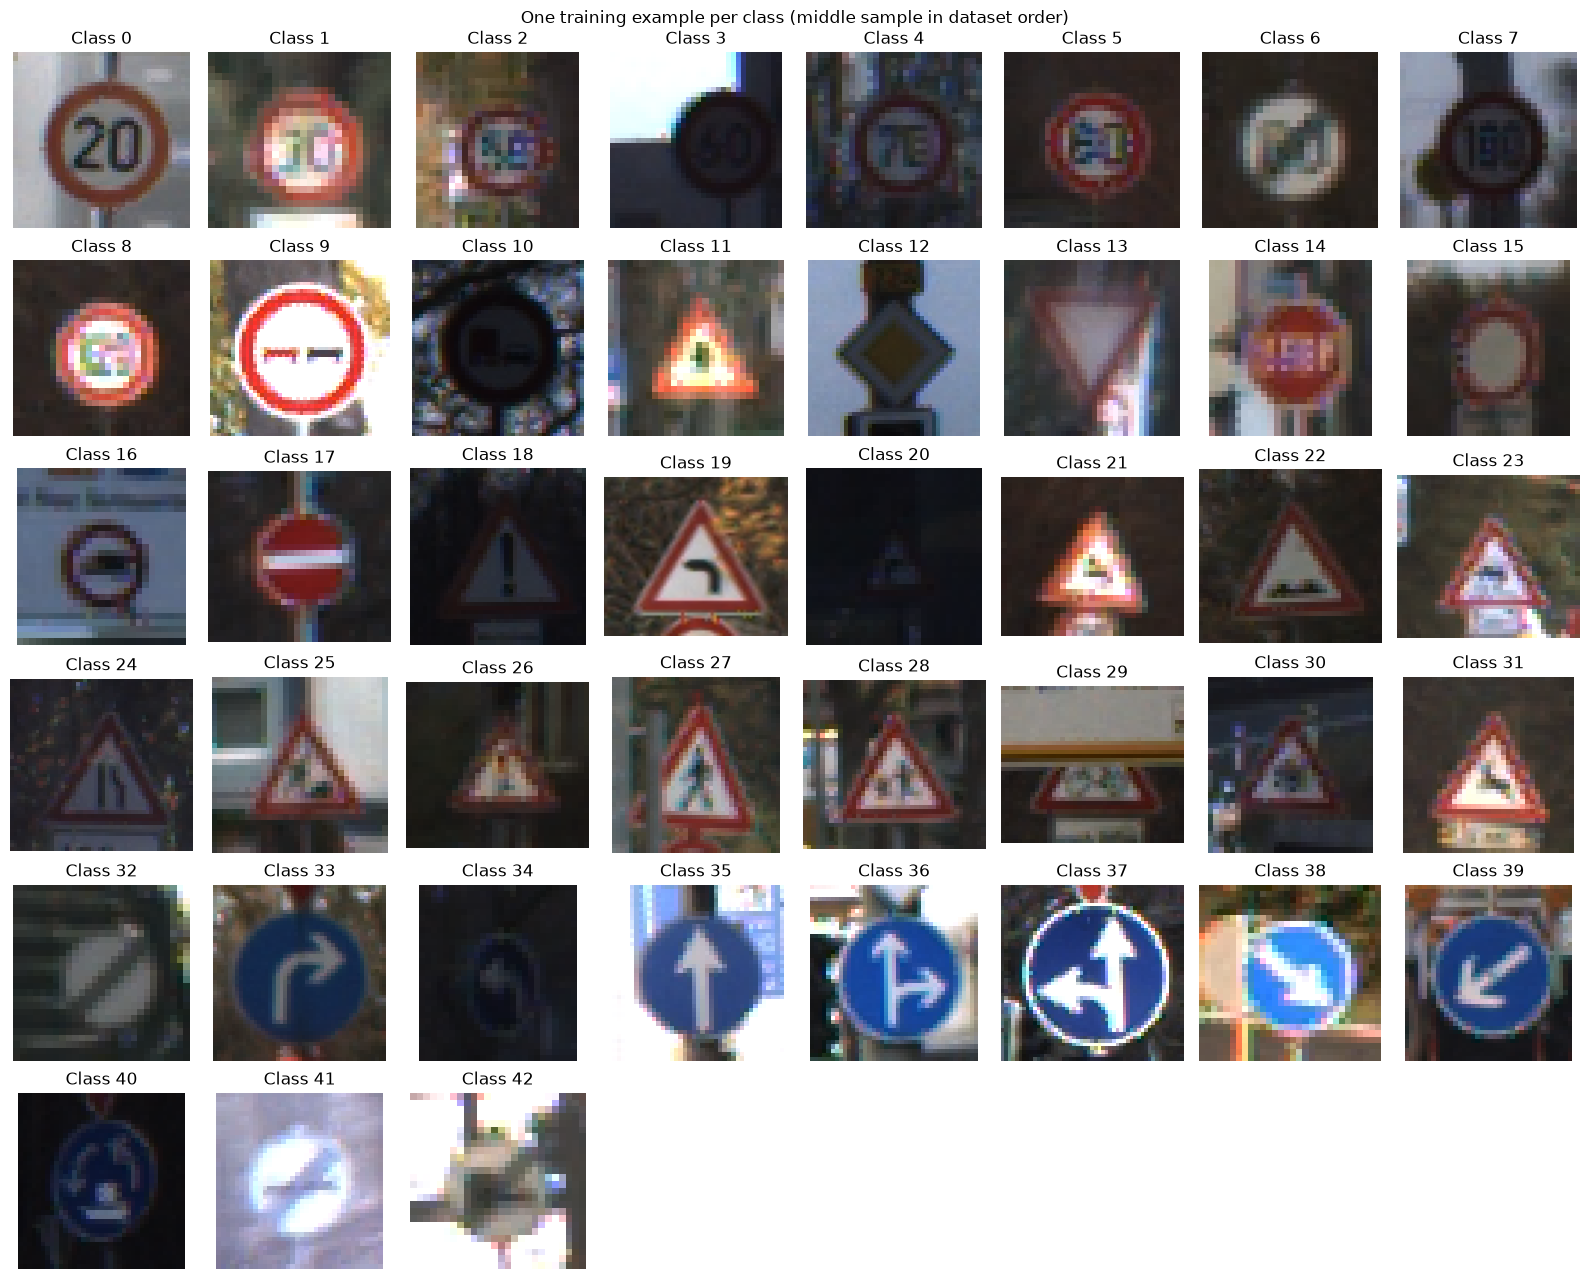

In [4]:
fig, axes = plt.subplots(6, 8, figsize=(16, 13))
for ax, class_id in zip(axes.flat, class_ids):
    indices = np.flatnonzero(train_labels == class_id)
    index = int(indices[len(indices) // 2])
    image, label = train_dataset[index]
    ax.imshow(image)
    ax.set_title(f"Class {label}")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("One training example per class (middle sample in dataset order)")
plt.tight_layout()
plt.show()

## Class Distribution

Training counts are calculated for each class ID. The chart shows how evenly the available training samples are distributed across the 43 classes.

The executed counts show an imbalance: classes 0, 19, and 37 each contain 150 training images, while classes 1 and 2 each contain 1,500. The largest class has ten times as many samples as the smallest.

In [5]:
class_counts = pd.Series(train_labels).value_counts().sort_index()
class_counts.index.name = "class_id"
class_counts.name = "training_samples"
display(class_counts.to_frame())
assert class_counts.sum() == len(train_dataset)

print(f"Smallest class: {class_counts.min():,} samples; IDs {class_counts[class_counts == class_counts.min()].index.tolist()}")
print(f"Largest class: {class_counts.max():,} samples; IDs {class_counts[class_counts == class_counts.max()].index.tolist()}")
print(f"Largest / smallest class count: {class_counts.max() / class_counts.min():.2f}")

,training_samples
class_id,
0,150
1,1500
2,1500
3,960
4,1320
5,1260
6,300
7,960
8,960


Smallest class: 150 samples; IDs [0, 19, 37]
Largest class: 1,500 samples; IDs [1, 2]
Largest / smallest class count: 10.00


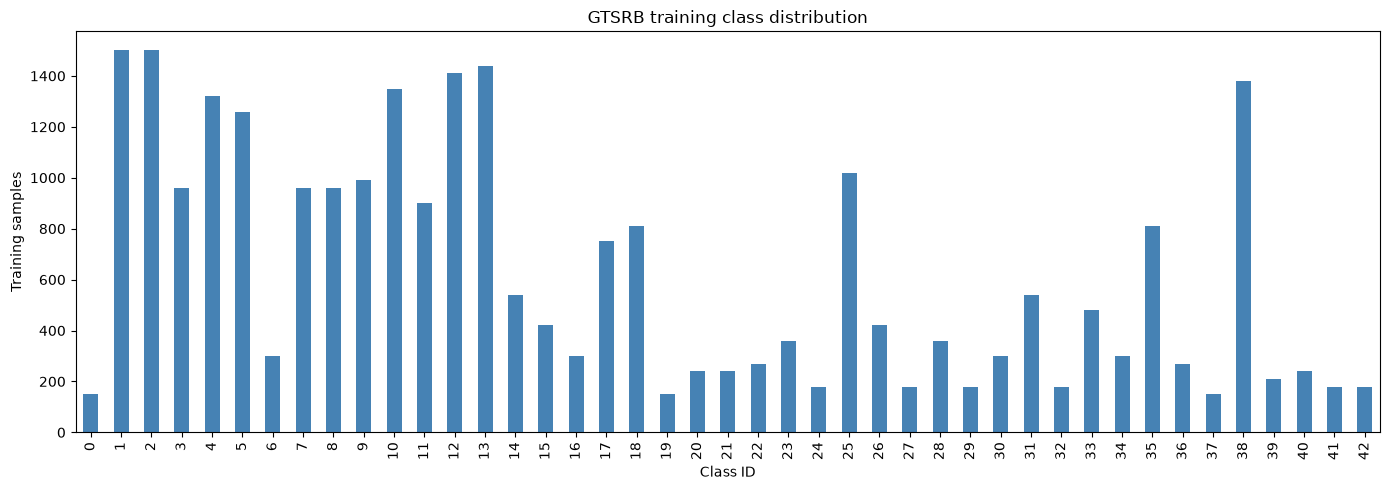

In [6]:
fig, ax = plt.subplots(figsize=(14, 5))
class_counts.plot.bar(ax=ax, color="steelblue")
ax.set(xlabel="Class ID", ylabel="Training samples", title="GTSRB training class distribution")
plt.tight_layout()
plt.show()

## Image Dimensions

Width and height are measured from the original images in both splits. Summary statistics and histograms describe the sizes before any preprocessing.

Training widths range from 25 to 243 pixels and heights from 25 to 225 pixels, with 2,489 distinct width–height pairs. Test widths range from 25 to 266 pixels and heights from 25 to 232 pixels, with 1,884 distinct pairs. Neither split has a uniform image size. Median width and height are both 43 pixels in each split; most images are much smaller than the largest examples.

In [7]:
size_records = []
for split, dataset in [("train", train_dataset), ("test", test_dataset)]:
    for index in range(len(dataset)):
        image, label = dataset[index]
        width, height = image.size
        size_records.append((split, index, label, width, height))

sizes = pd.DataFrame(size_records, columns=["split", "index", "class_id", "width", "height"])
sizes["pixels"] = sizes["width"] * sizes["height"]
display(sizes.head())
display(sizes.groupby("split")[["width", "height"]].describe().round(2))
for split, rows in sizes.groupby("split"):
    unique_sizes = rows[["width", "height"]].drop_duplicates().shape[0]
    print(f"{split}: {unique_sizes:,} distinct (width, height) pairs")
    print(f"All images have identical dimensions: {unique_sizes == 1}")
    print(f"Width range: {rows.width.min()}–{rows.width.max()} px; height range: {rows.height.min()}–{rows.height.max()} px")
    print("Most frequent dimensions:")
    display(rows.groupby(["width", "height"]).size().nlargest(5).rename("samples").to_frame())

,split,index,class_id,width,height,pixels
0,train,0,0,29,30,870
1,train,1,0,30,30,900
2,train,2,0,30,30,900
3,train,3,0,31,31,961
4,train,4,0,30,32,960


width                                                height         \
         count   mean    std   min   25%   50%   75%    max    count   mean   
split                                                                         
test   12630.0  50.51  25.09  25.0  34.0  43.0  58.0  266.0  12630.0  50.36   
train  26640.0  50.93  24.37  25.0  35.0  43.0  58.0  243.0  26640.0  50.37   

                                             
         std   min   25%   50%   75%    max  
split                                        
test   23.70  25.0  35.0  43.0  57.0  232.0  
train  23.16  25.0  35.0  43.0  58.0  225.0

test: 1,884 distinct (width, height) pairs
All images have identical dimensions: False
Width range: 25–266 px; height range: 25–232 px
Most frequent dimensions:


samples
width height         
33    33          135
32    32          134
29    29          132
31    31          127
      32          127

train: 2,489 distinct (width, height) pairs
All images have identical dimensions: False
Width range: 25–243 px; height range: 25–225 px
Most frequent dimensions:


,,samples
width,height,
30,30,256
31,31,254
32,32,250
35,35,247
38,38,246


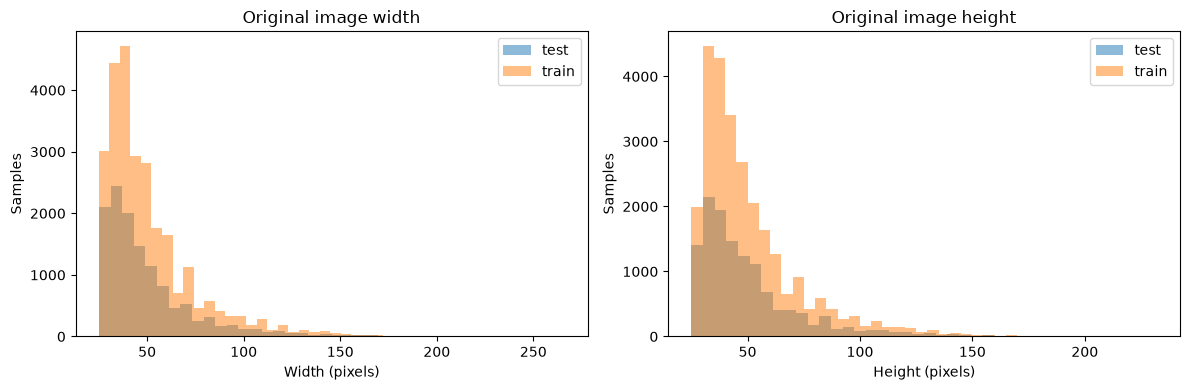

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split, rows in sizes.groupby("split"):
    axes[0].hist(rows.width, bins=40, alpha=0.5, label=split)
    axes[1].hist(rows.height, bins=40, alpha=0.5, label=split)
for ax, dimension in zip(axes, ["Width", "Height"]):
    ax.set(xlabel=f"{dimension} (pixels)", ylabel="Samples", title=f"Original image {dimension.lower()}")
    ax.legend()
plt.tight_layout()
plt.show()

## Visual Inspection

A fixed random selection from class 14 holds the sign category constant while showing different training samples. A second panel shows the smallest and largest training images by pixel count. Images use nearest-neighbor display interpolation so enlargement does not smooth their original pixels. These panels are a qualitative inspection, not a measured assessment of lighting, viewing angle, or image quality.

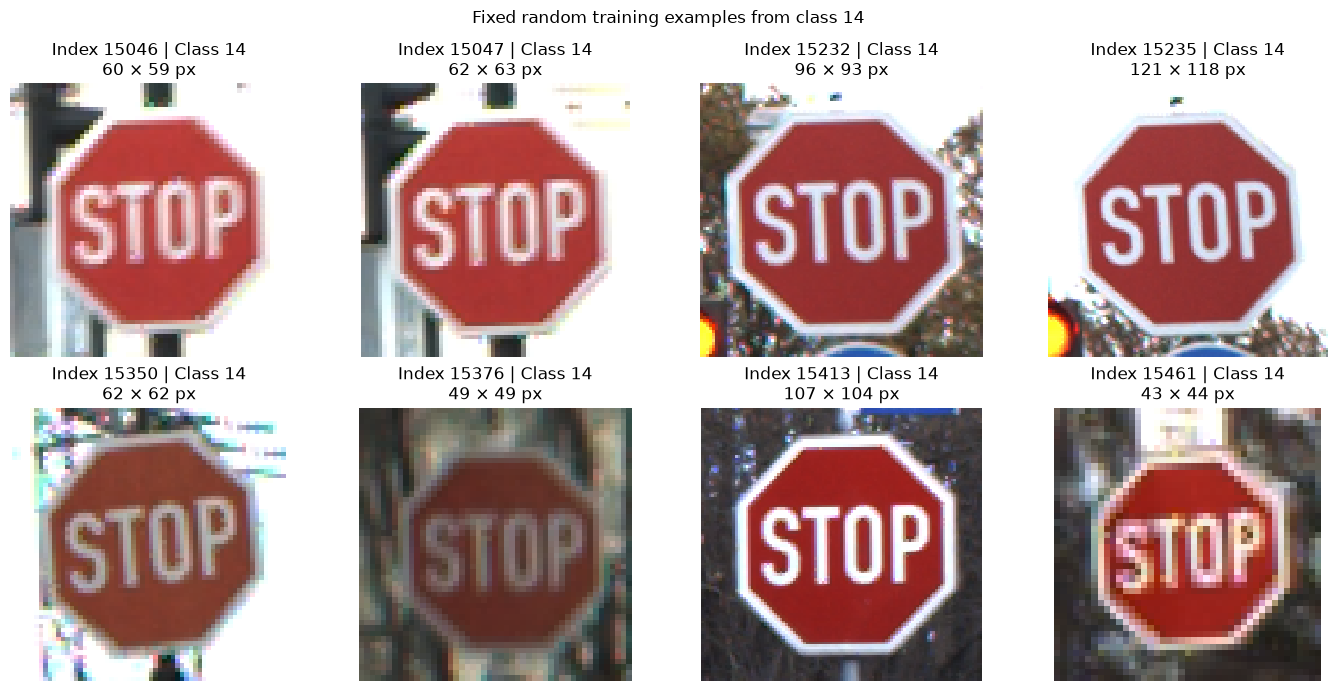

In [9]:
rng = np.random.default_rng(42)
inspection_indices = np.sort(rng.choice(np.flatnonzero(train_labels == 14), size=8, replace=False))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, index in zip(axes.flat, inspection_indices):
    image, label = train_dataset[int(index)]
    ax.imshow(image, interpolation="nearest")
    ax.set_title(f"Index {index} | Class {label}\n{image.width} × {image.height} px")
    ax.axis("off")
fig.suptitle("Fixed random training examples from class 14")
plt.tight_layout()
plt.show()

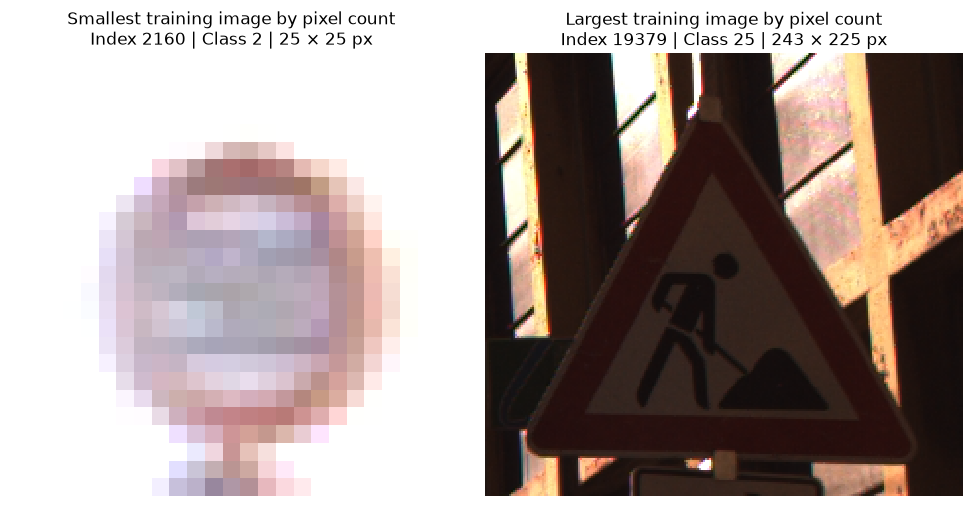

In [10]:
train_sizes = sizes[sizes["split"] == "train"]
resolution_examples = [train_sizes.loc[train_sizes.pixels.idxmin()], train_sizes.loc[train_sizes.pixels.idxmax()]]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, row, name in zip(axes, resolution_examples, ["Smallest", "Largest"]):
    index = int(row["index"])
    image, label = train_dataset[index]
    ax.imshow(image, interpolation="nearest")
    ax.set_title(f"{name} training image by pixel count\nIndex {index} | Class {label} | {image.width} × {image.height} px")
    ax.axis("off")
plt.tight_layout()
plt.show()

The displayed class-14 samples show visible differences in brightness and background: index 15376 is darker than index 15413, while index 15235 has a bright background and index 15413 has a dark, textured background. Lettering appears softer in index 15376 than in index 15413; index 15461 shows conspicuous pixelation when enlarged. These are visual impressions, without assigning a cause such as camera blur or exposure.

The resolution panel contrasts a 25 × 25 training image (index 2160) with a 243 × 225 image (index 19379). The small image has very little visible detail at this display scale. The larger example has a dark sign against a brighter structural background. Viewing angle is not quantified here, and these examples do not establish how frequently any visual condition occurs across the dataset.

## Initial Observations

- The downloaded training and test splits contain 26,640 and 12,630 samples respectively, covering 43 classes.
- Training classes are imbalanced, with counts from 150 to 1,500. Overall accuracy alone could hide differences in performance across classes in later experiments.
- Original image dimensions vary substantially. Both splits have a median width and height of 43 pixels, so a common input size will require a deliberate preprocessing choice.
- Selected training images visibly differ in brightness, surrounding background, resolution, and apparent sharpness. These examples support qualitative observations, not estimates of condition prevalence or recognition difficulty.
- This exploration does not measure model accuracy or robustness. No model, augmentation, or synthetic corruption is included.